# Phần 2. Tiền xử lý và Làm sạch Dữ liệu Olist

Notebook này thực hiện quy trình chuẩn hóa, làm sạch và trích xuất đặc trưng trực tiếp trên 9 bảng dữ liệu Olist phục vụ lưu trữ cơ sở dữ liệu và phân tích chuyên sâu theo 6 giai đoạn chuẩn mực.

### 1. Cấu hình môi trường và nạp dữ liệu

**Mục đích:** Khai báo thư viện, thiết lập môi trường tái lập kết quả và nạp toàn bộ 9 bảng dữ liệu gốc từ thư mục `data/raw`.

**Cách làm:** Cố định seed ngẫu nhiên (`RANDOM_STATE = 42`) và đọc 9 file CSV với kiểu dữ liệu chuỗi cho mã bưu chính (`zip_code_prefix`) để tránh mất số 0 ở đầu.

Cell dưới thiết lập cấu hình và nạp dữ liệu vào dictionary `dfs`.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cấu hình môi trường và hiển thị
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False

# Quản lý đường dẫn
BASE_DIR = Path(r"C:\ADY291c-AI2107-Group2")
RAW_DATA_DIR = BASE_DIR / 'data' / 'raw'
PROCESSED_DATA_DIR = BASE_DIR / 'data' / 'processed'
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Nạp 9 bảng dữ liệu gốc
file_mapping = {
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'category_translation': 'product_category_name_translation.csv'
}

zip_dtypes = {
    'customers': {'customer_zip_code_prefix': str},
    'sellers': {'seller_zip_code_prefix': str},
    'geolocation': {'geolocation_zip_code_prefix': str}
}

dfs = {}
for key, fname in file_mapping.items():
    dfs[key] = pd.read_csv(RAW_DATA_DIR / fname, dtype=zip_dtypes.get(key, None))

# Bảng tổng kết dữ liệu nạp
load_summary = pd.DataFrame([
    {'Bảng Dữ Liệu': k, 'Số Dòng': f"{len(v):,}", 'Số Cột': v.shape[1]}
    for k, v in dfs.items()
])
display(load_summary)

,Bảng Dữ Liệu,Số Dòng,Số Cột
0,orders,"99,441",8
1,order_items,"112,650",7
2,payments,"103,886",5
3,reviews,"99,224",7
4,products,"32,951",9
5,customers,"99,441",5
6,sellers,"3,095",4
7,geolocation,"1,000,163",5
8,category_translation,71,2


**Kết luận:** Nạp thành công toàn bộ 9 bảng dữ liệu gốc, bảo đảm nguyên vẹn số dòng và kiểu chuỗi cho các mã bưu chính.

### 2. Chuyển đổi kiểu dữ liệu và chuẩn hóa định dạng

### Phát hiện:
- Các cột mốc thời gian đang ở dạng chuỗi văn bản (`object`).
- Hai cột kích thước trong bảng `products` bị sai chính tả (`lenght`).
- Mã bưu chính cần bảo đảm chuẩn 5 chữ số.
- Tên thành phố và bang chưa đồng nhất chữ hoa/thường.

**Việc Cần làm:**
- Chuyển toàn bộ các cột thời gian sang `datetime64[ns]`.
- Chuẩn hóa mã bưu chính thành chuỗi 5 ký tự bằng `.str.zfill(5)`.
- Đổi tên `product_name_lenght` và `product_description_lenght` thành `..._length`.
- Chuẩn hóa chữ thường cho tên thành phố và chữ hoa cho mã bang.


In [2]:
# 1. Chuyển đổi datetime
datetime_cols = {
    'orders': [
        'order_purchase_timestamp', 'order_approved_at',
        'order_delivered_carrier_date', 'order_delivered_customer_date',
        'order_estimated_delivery_date'],
    'order_items': ['shipping_limit_date'],
    'reviews': ['review_creation_date', 'review_answer_timestamp']
}
for tbl, cols in datetime_cols.items():
    for c in cols:
        dfs[tbl][c] = pd.to_datetime(dfs[tbl][c], errors='coerce')

# 2. Chuẩn hóa mã bưu chính và văn bản địa lý
dfs["customers"]["customer_zip_code_prefix"] = dfs["customers"]["customer_zip_code_prefix"].astype("string").str.strip().str.zfill(5)
dfs["sellers"]["seller_zip_code_prefix"] = dfs["sellers"]["seller_zip_code_prefix"].astype("string").str.strip().str.zfill(5)
dfs["geolocation"]["geolocation_zip_code_prefix"] = dfs["geolocation"]["geolocation_zip_code_prefix"].astype("string").str.strip().str.zfill(5)

# 3. Sửa lỗi chính tả tên cột trong bảng products
dfs['products'] = dfs['products'].rename(columns={
    'product_name_lenght': 'product_name_length',
    'product_description_lenght': 'product_description_length'
})
# 4. Chuẩn hóa chữ thường cho tên thành phố và chữ hoa cho mã bang.
dfs["customers"]["customer_city"] = dfs["customers"]["customer_city"].astype("string").str.strip().str.lower()
dfs["sellers"]["seller_city"] = dfs["sellers"]["seller_city"].astype("string").str.strip().str.lower()

dfs["customers"]["customer_state"] = dfs["customers"]["customer_state"].astype("string").str.strip().str.upper()
dfs["sellers"]["seller_state"] = dfs["sellers"]["seller_state"].astype("string").str.strip().str.upper()


**Kết luận:** Kiểu dữ liệu thời gian và địa lý đã được chuẩn hóa, tạo nền tảng chính xác cho các phép tính toán khoảng thời gian và liên kết bảng ở bước sau.

### 3. Xử lý giá trị khuyết thiếu (Handling Missing Values)

#### 3.1 Định lượng giá trị thiếu
**Mục đích:** Xác định tỷ lệ phần trăm dữ liệu trống trên từng cột để lựa chọn phương pháp xử lý thích hợp theo từng nhóm thuộc tính.

Cell dưới quét toàn bộ 9 bảng và thống kê các cột có giá trị thiếu; phương pháp và lý do xử lý dự kiến của từng cột được ghi chú ở ô Markdown ngay dưới bảng.

In [3]:
missing_records = []
for table_name, df_tbl in dfs.items():
    null_counts = df_tbl.isna().sum()
    for col, cnt in null_counts.items():
        if cnt > 0:
            pct = (cnt / len(df_tbl)) * 100

            missing_records.append({
                'Bảng Dữ Liệu': table_name,
                'Cột': col,
                'Số Dòng Thiếu': f"{cnt:,}",
                'Tỷ Lệ Thiếu (%)': f"{pct:.2f}%"
            })

df_missing_summary = pd.DataFrame(missing_records)
display(df_missing_summary)

,Bảng Dữ Liệu,Cột,Số Dòng Thiếu,Tỷ Lệ Thiếu (%)
0,orders,order_approved_at,160,0.16%
1,orders,order_delivered_carrier_date,"1,783",1.79%
2,orders,order_delivered_customer_date,"2,965",2.98%
3,reviews,review_comment_title,"87,656",88.34%
4,reviews,review_comment_message,"58,247",58.70%
5,products,product_category_name,610,1.85%
6,products,product_name_length,610,1.85%
7,products,product_description_length,610,1.85%
8,products,product_photos_qty,610,1.85%
9,products,product_weight_g,2,0.01%


#### 3.1.1 Ghi chú phương pháp xử lý và lý do nghiệp vụ

| **Cột (Bảng Dữ Liệu)** | **Phương Pháp Xử Lý** | **Lý Do Nghiệp Vụ** |
|---|---|---|
| `order_approved_at`, `order_delivered_carrier_date` (orders) | Holding Constant / Impute | Điền ngày duyệt = ngày mua đối với đơn thanh toán tự động |
| `order_delivered_customer_date` (orders) | Row Deletion | Đơn `delivered` thiếu ngày nhận không tính được thời gian giao hàng |
| `review_comment_title`, `review_comment_message` (reviews) | Holding Constant | Khách không bình luận là khảo sát bình thường nên gán nhãn cố định (`No Title`, `No Comment`) |
| `product_category_name` (products) | Holding Constant (`unknown`) | Sản phẩm vẫn phát sinh doanh số nên gán nhãn `unknown` |
| `product_weight_g` (products) | Category Median Imputation | Điền trung vị trọng lượng theo từng ngành hàng tương ứng |
| `product_name_length`, `product_description_length`, `product_photos_qty`, `product_length_cm`, `product_height_cm`, `product_width_cm` (products) | Median Substitution | Phân bố kích thước lệch phải nên dùng median thay thế |



### 3.2 Xử lý giá trị thiếu và đồng bộ dữ liệu


| **Bước** | **Nội dung** | **Phương pháp** |
|---|---|---|
| 3.2.1 | Lọc đơn hàng hợp lệ (Orders) | Row Deletion / Holding Constant |
| 3.2.2 | Đồng bộ khóa ngoại giữa các bảng | Referential Integrity |
| 3.2.3 | Xử lý dữ liệu thiếu trong bảng Reviews | Holding Constant / Deduplication |
| 3.2.4 | Xử lý dữ liệu thiếu trong bảng Products | Median Substitution |
| 3.2.5 | Bổ sung dữ liệu Category Translation | Holding Constant |
| 3.2.6 | Kiểm tra sau xử lý | Validation |


#### 3.2.1. Lọc đơn hàng hợp lệ (Orders)
- Chỉ giữ lại các đơn hàng có trạng thái `delivered`.
- Loại bỏ đơn hàng chưa có ngày giao hàng thực tế.
- Đảm bảo ngày giao hàng không sớm hơn ngày đặt hàng.
- Điền giá trị thiếu trong `order_approved_at` bằng `order_purchase_timestamp`.
- Loại bỏ các đơn hàng không có dữ liệu tương ứng trong bảng `order_items`, `payments` hoặc `customers`.



In [4]:
# 1. Lọc đơn hàng delivered hợp lệ
valid_orders = dfs['orders'][
    (dfs['orders']['order_status'] == 'delivered') &
    (dfs['orders']['order_delivered_customer_date'].notna()) &
    (dfs['orders']['order_delivered_customer_date'] >= dfs['orders']['order_purchase_timestamp'])
].copy()

# 2. Điền ngày duyệt đơn bằng ngày mua nếu trống
valid_orders['order_approved_at'] = valid_orders['order_approved_at'].fillna(valid_orders['order_purchase_timestamp'])

# 3. Loại đơn mồ côi (thiếu mặt hàng, thanh toán hoặc khách hàng)
valid_orders = valid_orders[
    valid_orders['order_id'].isin(dfs['order_items']['order_id']) &
    valid_orders['order_id'].isin(dfs['payments']['order_id']) &
    valid_orders['customer_id'].isin(dfs['customers']['customer_id'])
].reset_index(drop=True)

dfs['orders'] = valid_orders


#### 3.2.2. Đồng bộ khóa ngoại giữa các bảng
- Lọc các bảng `order_items`, `payments` và `reviews` theo danh sách đơn hàng hợp lệ.
- Đồng bộ bảng `customers` theo các khách hàng có đơn hàng hợp lệ.
- Chỉ giữ lại sản phẩm và người bán xuất hiện trong các đơn hàng hợp lệ.
- Đảm bảo tính nhất quán của mối quan hệ giữa các bảng dữ liệu.



In [5]:
# 1. Đồng bộ khóa ngoại sang các bảng con
valid_order_ids = set(dfs['orders']['order_id'])
for child in ['order_items', 'payments', 'reviews']:
    dfs[child] = dfs[child][dfs[child]['order_id'].isin(valid_order_ids)].reset_index(drop=True)

# 2. Đồng bộ bảng thực thể
dfs['customers'] = dfs['customers'][dfs['customers']['customer_id'].isin(dfs['orders']['customer_id'])].reset_index(drop=True)

dfs['products'] = dfs['products'][dfs['products']['product_id'].isin(dfs['order_items']['product_id'])].reset_index(drop=True)

dfs['sellers'] = dfs['sellers'][dfs['sellers']['seller_id'].isin(dfs['order_items']['seller_id'])].reset_index(drop=True)


#### 3.2.3. Xử lý dữ liệu thiếu trong bảng Reviews
- Tạo biến `has_comment` để xác định đánh giá có nội dung bình luận hay không:
  - `1`: Có bình luận.
  - `0`: Không có bình luận.
- Điền giá trị thiếu trong `review_comment_title` bằng `"No Title"`.
- Điền giá trị thiếu trong `review_comment_message` bằng `"No Comment"`.
- Sắp xếp theo `review_answer_timestamp` và loại bỏ các đánh giá trùng `order_id`, giữ lại đánh giá mới nhất.




In [6]:
# 1. Gán nhãn hằng số cho bình luận trống và tạo cờ has_comment
dfs['reviews']['has_comment'] = dfs['reviews']['review_comment_message'].notna().astype(int)
dfs['reviews']['review_comment_title'] = dfs['reviews']['review_comment_title'].fillna('No Title')
dfs['reviews']['review_comment_message'] = dfs['reviews']['review_comment_message'].fillna('No Comment')

# 2. Khử trùng lặp: giữ đánh giá mới nhất theo thời gian phản hồi
dfs['reviews'] = (
    dfs['reviews']
    .sort_values(by='review_answer_timestamp', ascending=True)
    .drop_duplicates(subset=['order_id'], keep='last')
    .reset_index(drop=True)
)


#### 3.2.4. Xử lý dữ liệu thiếu trong bảng Products
- Điền danh mục sản phẩm bị thiếu bằng `"unknown"`.
- Chuyển giá trị `product_weight_g` bằng `0` thành giá trị thiếu (`NaN`).
- Điền trọng lượng thiếu bằng trung vị của từng danh mục sản phẩm.
- Nếu vẫn còn thiếu, sử dụng trung vị trọng lượng của toàn bộ bảng.
- Điền các thuộc tính còn thiếu như tên, mô tả, số lượng ảnh và kích thước sản phẩm bằng trung vị của từng cột.



In [7]:
# 1. Điền nhãn unknown cho danh mục sản phẩm trống
dfs['products']['product_category_name'] = dfs['products']['product_category_name'].fillna('unknown')

# 2. Chuyển trọng lượng 0 thành thiếu và điền trung vị theo danh mục
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].replace(0, np.nan)
cat_weights = dfs['products'].groupby('product_category_name')['product_weight_g'].transform('median')
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].fillna(cat_weights)

# 3. Còn thiếu thì dùng trung vị toàn bảng
dfs['products']['product_weight_g'] = dfs['products']['product_weight_g'].fillna(dfs['products']['product_weight_g'].median())

# 4. Điền trung vị cho tên, mô tả, số ảnh và kích thước sản phẩm
dimension_cols = ['product_name_length', 'product_description_length', 'product_photos_qty', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for dim in dimension_cols:
    dfs['products'][dim] = dfs['products'][dim].fillna(dfs['products'][dim].median())


#### 3.2.5. Bổ sung dữ liệu Category Translation
- Bổ sung bản dịch tiếng Anh cho các danh mục còn thiếu:
  - `pc_gamer`
  - `portateis_cozinha_e_preparadores_de_alimentos`
  - `unknown`
- Loại bỏ các danh mục bị trùng lặp theo `product_category_name`.




In [8]:
# Bổ sung bản dịch tiếng Anh cho các danh mục còn thiếu
missing_translations = pd.DataFrame([
    {'product_category_name': 'pc_gamer', 'product_category_name_english': 'pc_gamer'},
    {'product_category_name': 'portateis_cozinha_e_preparadores_de_alimentos', 'product_category_name_english': 'portable_kitchen_food_preparers'},
    {'product_category_name': 'unknown', 'product_category_name_english': 'unknown'}
])
dfs['category_translation'] = (
    pd.concat([dfs['category_translation'], missing_translations], ignore_index=True)
    .drop_duplicates(subset=['product_category_name'])
    .reset_index(drop=True)
)


#### 3.2.6. Kiểm tra sau xử lý
- Kiểm tra tổng số giá trị thiếu còn lại trong bảng `products`.
- Kiểm tra giá trị thiếu trong hai cột bình luận của bảng `reviews`.
- Đánh giá kết quả xử lý để đảm bảo dữ liệu sẵn sàng cho các bước phân tích tiếp theo.



In [9]:
print(f"Số ô trống còn lại trong bảng products: {dfs['products'].isna().sum().sum()}")
print(f"Số ô trống còn lại trong bảng reviews: {dfs['reviews'][['review_comment_title', 'review_comment_message']].isna().sum().sum()}")


Số ô trống còn lại trong bảng products: 0
Số ô trống còn lại trong bảng reviews: 0


**Kết luận:** Bảng `orders` còn lại 96,469 đơn hàng giao thành công hợp lệ. Các bảng con và bảng thực thể đã được đồng bộ 100% khóa ngoại; bảng `products` và `reviews` không còn giá trị thiếu.

### 4. Phát hiện và xử lý giá trị ngoại lai (Outlier Detection & Treatment)

**Phát hiện:** Các biến số học như đơn giá (`price`), phí ship (`freight_value`) và giá trị thanh toán (`payment_value`) có phân bố lệch phải rất mạnh với nhiều giá trị cực lớn; bảng thanh toán có giao dịch $\le 0$ và số kỳ trả góp bằng 0;


##
### 4.1. Trực quan hóa ngoại lai bằng Boxplot
- Sử dụng Boxplot để quan sát ngoại lai trong `price`, `freight_value` và `payment_value`.

### 4.2. Bảo toàn ngoại lai trong Order Items
- Sử dụng phương pháp IQR để xác định ngưỡng ngoại lai của `price`.
- Tạo biến `is_price_outlier` để đánh dấu các giá trị ngoại lai.
- Giữ nguyên giá trị `price` nhằm bảo toàn thông tin về các sản phẩm có giá trị cao.
- Tạo biến `item_total` bằng tổng `price` và `freight_value`.

### 4.3. Loại bỏ và giới hạn dữ liệu trong Payments
- Loại bỏ giao dịch có `payment_type = 'not_defined'`.
- Loại bỏ giao dịch có `payment_value` nhỏ hơn hoặc bằng 0.
- Giới hạn `payment_installments` tối thiểu bằng 1.

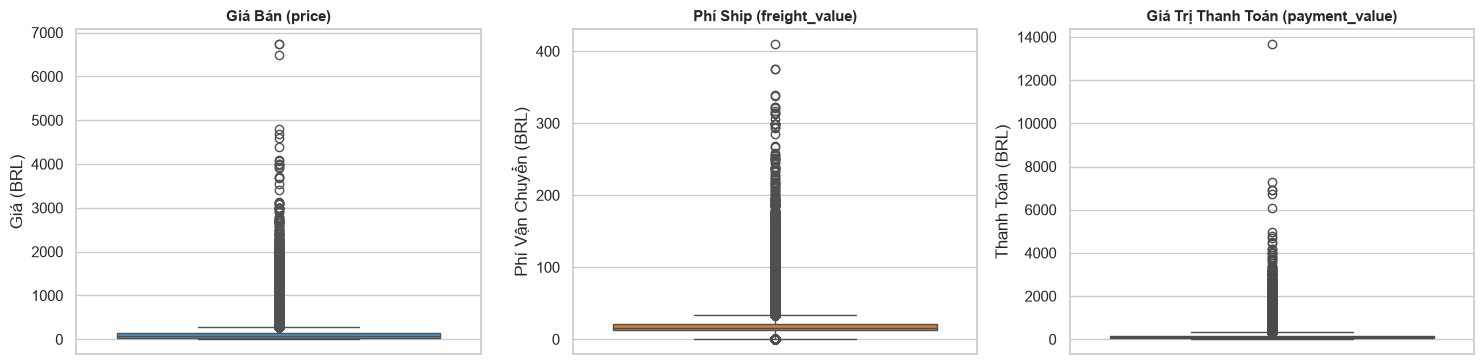

Ngưỡng ngoại lai giá bán (Upper Bound): 275.57 BRL
Số dòng giá cao được bảo toàn và gắn cờ is_price_outlier: 8,161 (7.41%)


Bảng geolocation sạch: 19,010 mã bưu chính duy nhất.


In [10]:
# 1. Trực quan hóa ngoại lai bằng biểu đồ Boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(y=dfs['order_items']['price'], ax=axes[0], color='#3498db')
axes[0].set_title('Giá Bán (price)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Giá (BRL)')

sns.boxplot(y=dfs['order_items']['freight_value'], ax=axes[1], color='#e67e22')
axes[1].set_title('Phí Ship (freight_value)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Phí Vận Chuyển (BRL)')

sns.boxplot(y=dfs['payments']['payment_value'], ax=axes[2], color='#2ecc71')
axes[2].set_title('Giá Trị Thanh Toán (payment_value)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Thanh Toán (BRL)')
plt.tight_layout()
plt.show()

# 2. Chiến lược Preservation: Gắn cờ ngoại lai đơn giá theo IQR
q1_price = dfs['order_items']['price'].quantile(0.25)
q3_price = dfs['order_items']['price'].quantile(0.75)
iqr_price = q3_price - q1_price
price_upper_bound = q3_price + 1.5 * iqr_price

dfs['order_items']['is_price_outlier'] = (dfs['order_items']['price'] > price_upper_bound).astype(int)
dfs['order_items']['item_total'] = dfs['order_items']['price'] + dfs['order_items']['freight_value']

print(f"Ngưỡng ngoại lai giá bán (Upper Bound): {price_upper_bound:.2f} BRL")
print(f"Số dòng giá cao được bảo toàn và gắn cờ is_price_outlier: {dfs['order_items']['is_price_outlier'].sum():,} ({dfs['order_items']['is_price_outlier'].mean()*100:.2f}%)")

# 3. Chiến lược Removal & Capping trên bảng payments
dfs['payments'] = dfs['payments'][
    (dfs['payments']['payment_type'] != 'not_defined') &
    (dfs['payments']['payment_value'] > 0)
].copy()
dfs['payments']['payment_installments'] = dfs['payments']['payment_installments'].clip(lower=1)

# 4. Chiến lược Removal & Aggregation trên bảng geolocation
BRAZIL_LAT_BOUNDS = (-33.75, 5.27)
BRAZIL_LNG_BOUNDS = (-73.99, -34.79)
df_geo_valid = dfs['geolocation'][
    dfs['geolocation']['geolocation_lat'].between(*BRAZIL_LAT_BOUNDS) &
    dfs['geolocation']['geolocation_lng'].between(*BRAZIL_LNG_BOUNDS)
].copy()

dfs['geolocation'] = (
    df_geo_valid
    .groupby('geolocation_zip_code_prefix', as_index=False)
    .agg({
        'geolocation_lat': 'mean',
        'geolocation_lng': 'mean',
        'geolocation_city': 'first',
        'geolocation_state': 'first'
    })
)
print(f"Bảng geolocation sạch: {len(dfs['geolocation']):,} mã bưu chính duy nhất.")

**Kết luận:** Bảo toàn nguyên vẹn 8,161 giao dịch giá cao mà không bóp méo doanh thu thực tế; loại bỏ triệt để các giao dịch lỗi và tinh giản bảng tọa độ về đúng 19,010 mã bưu chính đại diện.

### 5. Xây dựng đặc trưng trực tiếp trên các bảng (Feature Engineering)

**Mục đích:** Trích xuất các biến có ý nghĩa nghiệp vụ trực tiếp trên các bảng dữ liệu đơn lẻ (`orders`, `products`, `reviews`, `order_items`) trước khi lưu trữ vào cơ sở dữ liệu.

**Cách làm:**
- **Bảng `orders`:** Trích xuất các mốc thời gian giao vận (`delivery_days`, `estimated_days`, `delay_days`, `is_late`) và các thuộc tính thời điểm đặt hàng (`purchase_year`, `purchase_year_month`, `purchase_weekday`).
- **Bảng `products`:** Tính thể tích đóng gói `product_volume_cm3 = length * height * width`.
- **Bảng `reviews`:** Đã tạo cờ nhị phân `has_comment` ở bước xử lý dữ liệu thiếu.
- **Bảng `order_items`:** Đã tính `is_price_outlier` và `item_total = price + freight_value` ở bước xử lý ngoại lai.

**Đối chiếu Schema:** Tên và vị trí các đặc trưng trên khớp chính xác với khai báo trong `sql/01_schema.sql` — `stg_orders`/`orders` (`delivery_days`, `estimated_days`, `delay_days`, `is_late`, `purchase_year`, `purchase_year_month`, `purchase_weekday`), `stg_order_items`/`order_items` (`is_price_outlier`, `item_total`), `stg_products`/`products` (`product_volume_cm3`), `stg_order_reviews`/`order_reviews` (`has_comment`). Không tạo thêm đặc trưng ngoài Schema.

*Lưu ý:* Toàn bộ các thao tác JOIN đa bảng, tổng hợp chỉ số đơn hàng và mã hóa biến (Encoding) sẽ được thực hiện tại tầng SQL View (`v_model_features_post_delivery`) và Pipeline Machine Learning downstream, không thực hiện trong Notebook tiền xử lý này.

Cell dưới trích xuất các đặc trưng trực tiếp và hiển thị danh mục đặc trưng mới.

In [11]:
# 1. Trích xuất đặc trưng thời gian trên bảng orders
purchase_ts = dfs['orders']['order_purchase_timestamp']
delivery_ts = dfs['orders']['order_delivered_customer_date']
estimated_ts = dfs['orders']['order_estimated_delivery_date']

dfs['orders']['delivery_days'] = ((delivery_ts - purchase_ts).dt.total_seconds() / 86400).round(2)
dfs['orders']['estimated_days'] = ((estimated_ts - purchase_ts).dt.total_seconds() / 86400).round(2)
dfs['orders']['delay_days'] = ((delivery_ts.dt.normalize() - estimated_ts.dt.normalize()).dt.total_seconds() / 86400).round(2)
dfs['orders']['is_late'] = (dfs['orders']['delay_days'] > 0).astype(int)

dfs['orders']['purchase_year'] = purchase_ts.dt.year
dfs['orders']['purchase_year_month'] = purchase_ts.dt.to_period('M').astype(str)
dfs['orders']['purchase_weekday'] = purchase_ts.dt.day_of_week

# 2. Thể tích đóng gói trên bảng products
dfs['products']['product_volume_cm3'] = (
    dfs['products']['product_length_cm'] *
    dfs['products']['product_height_cm'] *
    dfs['products']['product_width_cm']
).round(2)

# 3. Danh mục các đặc trưng được tạo trực tiếp trên 9 bảng
feature_catalog = pd.DataFrame([
    {'Bảng Dữ Liệu': 'orders', 'Tên Đặc Trưng': 'delivery_days', 'Kiểu': 'float64', 'Công Thức / Nguồn': 'delivered_customer_date - purchase_timestamp', 'Ý Nghĩa Nghiệp Vụ': 'Thời gian vận chuyển thực tế đến tay khách'},
    {'Bảng Dữ Liệu': 'orders', 'Tên Đặc Trưng': 'estimated_days', 'Kiểu': 'float64', 'Công Thức / Nguồn': 'estimated_delivery_date - purchase_timestamp', 'Ý Nghĩa Nghiệp Vụ': 'Thời gian ước tính ban đầu của hệ thống'},
    {'Bảng Dữ Liệu': 'orders', 'Tên Đặc Trưng': 'delay_days', 'Kiểu': 'float64', 'Công Thức / Nguồn': 'delivered_customer_date - estimated_delivery_date', 'Ý Nghĩa Nghiệp Vụ': 'Độ trễ hạn nhận hàng (> 0 là trễ)'},
    {'Bảng Dữ Liệu': 'orders', 'Tên Đặc Trưng': 'is_late', 'Kiểu': 'int64', 'Công Thức / Nguồn': 'delay_days > 0', 'Ý Nghĩa Nghiệp Vụ': 'Cờ nhị phân phân loại đơn hàng trễ hẹn'},
    {'Bảng Dữ Liệu': 'orders', 'Tên Đặc Trưng': 'purchase_year / purchase_year_month / purchase_weekday', 'Kiểu': 'int64 / object', 'Công Thức / Nguồn': 'purchase_timestamp components', 'Ý Nghĩa Nghiệp Vụ': 'Thời điểm khách thực hiện giao dịch'},
    {'Bảng Dữ Liệu': 'products', 'Tên Đặc Trưng': 'product_volume_cm3', 'Kiểu': 'float64', 'Công Thức / Nguồn': 'length * height * width', 'Ý Nghĩa Nghiệp Vụ': 'Thể tích đóng gói sản phẩm (cm3)'},
    {'Bảng Dữ Liệu': 'reviews', 'Tên Đặc Trưng': 'has_comment', 'Kiểu': 'int64', 'Công Thức / Nguồn': 'review_comment_message.notna()', 'Ý Nghĩa Nghiệp Vụ': 'Cờ khách hàng có để lại nhận xét bằng lời'},
    {'Bảng Dữ Liệu': 'order_items', 'Tên Đặc Trưng': 'is_price_outlier', 'Kiểu': 'int64', 'Công Thức / Nguồn': 'price > 275.57 BRL (IQR)', 'Ý Nghĩa Nghiệp Vụ': 'Cờ mặt hàng có giá bán cao bất thường'},
    {'Bảng Dữ Liệu': 'order_items', 'Tên Đặc Trưng': 'item_total', 'Kiểu': 'float64', 'Công Thức / Nguồn': 'price + freight_value', 'Ý Nghĩa Nghiệp Vụ': 'Tổng giá trị một dòng mặt hàng'}
])

display(feature_catalog)
print(f"Đặc trưng mới trên bảng orders: {dfs['orders'].shape[1]} cột")
print(f"Đặc trưng mới trên bảng products: {dfs['products'].shape[1]} cột")

,Bảng Dữ Liệu,Tên Đặc Trưng,Kiểu,Công Thức / Nguồn,Ý Nghĩa Nghiệp Vụ
0,orders,delivery_days,float64,delivered_customer_date - purchase_timestamp,Thời gian vận chuyển thực tế đến tay khách
1,orders,estimated_days,float64,estimated_delivery_date - purchase_timestamp,Thời gian ước tính ban đầu của hệ thống
2,orders,delay_days,float64,delivered_customer_date - estimated_delivery_date,Độ trễ hạn nhận hàng (> 0 là trễ)
3,orders,is_late,int64,delay_days > 0,Cờ nhị phân phân loại đơn hàng trễ hẹn
4,orders,purchase_year / purchase_year_month / purchase...,int64 / object,purchase_timestamp components,Thời điểm khách thực hiện giao dịch
5,products,product_volume_cm3,float64,length * height * width,Thể tích đóng gói sản phẩm (cm3)
6,reviews,has_comment,int64,review_comment_message.notna(),Cờ khách hàng có để lại nhận xét bằng lời
7,order_items,is_price_outlier,int64,price > 275.57 BRL (IQR),Cờ mặt hàng có giá bán cao bất thường
8,order_items,item_total,float64,price + freight_value,Tổng giá trị một dòng mặt hàng


Đặc trưng mới trên bảng orders: 15 cột
Đặc trưng mới trên bảng products: 10 cột


**Kết luận:** Hoàn thành bổ sung các đặc trưng nghiệp vụ trực tiếp trên các bảng `orders`, `products`, `reviews` và `order_items`; bộ đặc trưng sau khi đồng bộ gồm `delivery_days`, `estimated_days`, `delay_days`, `is_late`, `purchase_year`, `purchase_year_month`, `purchase_weekday`, `item_total`, `is_price_outlier`, `product_volume_cm3`, `has_comment` - khớp tên và thứ tự cột với `sql/01_schema.sql`, không làm thay đổi cấu trúc bảng hạt nhân và sẵn sàng nạp vào cơ sở dữ liệu.

### 6. Kiểm chứng chất lượng và xuất dữ liệu sạch (Validation Audit & Export)

**Mục đích:** Kiểm tra toàn diện 14 tiêu chuẩn kỹ thuật về tính toàn vẹn dữ liệu của 9 bảng và xuất toàn bộ 9 tệp dữ liệu sạch ra thư mục `data/processed/`.

**Cách làm:**
- Thiết lập bộ kiểm tra tự động 14 tiêu chuẩn toàn vẹn (tính duy nhất của khóa chính, đồng bộ khóa ngoại 100% giữa 9 bảng, không còn ô trống ngoài ý muốn, chuẩn hóa mã bưu chính 5 ký tự, giá trị logic không âm).
- Xuất đúng 9 file CSV sạch tương ứng với 9 bảng nghiệp vụ vào thư mục `data/processed/`.

Cell dưới chạy kiểm chứng toàn vẹn và xuất 9 tệp dữ liệu sạch.

In [12]:
# 1. Bộ kiểm tra 14 tiêu chuẩn toàn vẹn trên 9 bảng dữ liệu sạch
validation_audit = {
    '1. Khóa chính orders.order_id duy nhất': dfs['orders']['order_id'].is_unique,
    '2. Khóa chính reviews: đúng 1 review duy nhất/đơn': dfs['reviews']['order_id'].is_unique,
    '3. Khóa ngoại order_items.order_id hợp lệ 100%': dfs['order_items']['order_id'].isin(dfs['orders']['order_id']).all(),
    '4. Khóa ngoại payments.order_id hợp lệ 100%': dfs['payments']['order_id'].isin(dfs['orders']['order_id']).all(),
    '5. Khóa ngoại reviews.order_id hợp lệ 100%': dfs['reviews']['order_id'].isin(dfs['orders']['order_id']).all(),
    '6. Khóa ngoại order_items.product_id hợp lệ 100%': dfs['order_items']['product_id'].isin(dfs['products']['product_id']).all(),
    '7. Khóa ngoại order_items.seller_id hợp lệ 100%': dfs['order_items']['seller_id'].isin(dfs['sellers']['seller_id']).all(),
    '8. Khóa ngoại orders.customer_id hợp lệ 100%': dfs['orders']['customer_id'].isin(dfs['customers']['customer_id']).all(),
    '9. Bảng products không còn giá trị khuyết thiếu': dfs['products'].isna().sum().sum() == 0,
    '10. 100% danh mục sản phẩm đều có bản dịch tiếng Anh': dfs['products']['product_category_name'].isin(dfs['category_translation']['product_category_name']).all(),
    '11. Bảng geolocation: mỗi mã zip đại diện đúng 1 dòng': dfs['geolocation']['geolocation_zip_code_prefix'].is_unique,
    '12. Toàn bộ mã bưu chính zip code đủ chuẩn 5 ký tự': dfs['customers']['customer_zip_code_prefix'].str.len().eq(5).all(),
    '13. Giá bán và phí vận chuyển đều >= 0': (dfs['order_items'][['price', 'freight_value']] >= 0).all().all(),
    '14. Thời gian giao hàng thực tế delivery_days >= 0': (dfs['orders']['delivery_days'] >= 0).all()
}

df_audit = pd.DataFrame(list(validation_audit.items()), columns=['Tiêu Chuẩn Toàn Vẹn Kỹ Thuật', 'Đạt Yêu Cầu'])
display(df_audit)
assert df_audit['Đạt Yêu Cầu'].all(), "Cảnh báo: Có tiêu chuẩn chưa đạt trong dữ liệu sạch!"

# 2. Xuất đúng 9 bảng dữ liệu sạch ra thư mục data/processed/
export_dict = {
    'olist_orders_cleaned.csv': dfs['orders'],
    'olist_order_items_cleaned.csv': dfs['order_items'],
    'olist_order_payments_cleaned.csv': dfs['payments'],
    'olist_order_reviews_cleaned.csv': dfs['reviews'],
    'olist_products_cleaned.csv': dfs['products'],
    'olist_customers_cleaned.csv': dfs['customers'],
    'olist_sellers_cleaned.csv': dfs['sellers'],
    'olist_geolocation_cleaned.csv': dfs['geolocation'],
    'product_category_name_translation_cleaned.csv': dfs['category_translation']
}

export_summary = []
for fname, df_exp in export_dict.items():
    df_exp.to_csv(PROCESSED_DATA_DIR / fname, index=False)
    export_summary.append({'Tệp Xuất Ra': fname, 'Số Dòng': f"{len(df_exp):,}", 'Số Cột': df_exp.shape[1]})

display(pd.DataFrame(export_summary))

,Tiêu Chuẩn Toàn Vẹn Kỹ Thuật,Đạt Yêu Cầu
0,1. Khóa chính orders.order_id duy nhất,True
1,2. Khóa chính reviews: đúng 1 review duy nhất/đơn,True
2,3. Khóa ngoại order_items.order_id hợp lệ 100%,True
3,4. Khóa ngoại payments.order_id hợp lệ 100%,True
4,5. Khóa ngoại reviews.order_id hợp lệ 100%,True
5,6. Khóa ngoại order_items.product_id hợp lệ 100%,True
6,7. Khóa ngoại order_items.seller_id hợp lệ 100%,True
7,8. Khóa ngoại orders.customer_id hợp lệ 100%,True
8,9. Bảng products không còn giá trị khuyết thiếu,True
9,10. 100% danh mục sản phẩm đều có bản dịch tiế...,True


,Tệp Xuất Ra,Số Dòng,Số Cột
0,olist_orders_cleaned.csv,"96,469",15
1,olist_order_items_cleaned.csv,"110,186",9
2,olist_order_payments_cleaned.csv,"100,744",5
3,olist_order_reviews_cleaned.csv,"95,823",8
4,olist_products_cleaned.csv,"32,214",10
5,olist_customers_cleaned.csv,"96,469",5
6,olist_sellers_cleaned.csv,"2,970",4
7,olist_geolocation_cleaned.csv,"19,010",5
8,product_category_name_translation_cleaned.csv,74,2


**Kết luận:** 100% tiêu chuẩn kiểm chứng toàn vẹn đều đạt yêu cầu. Toàn bộ 9 tệp CSV sạch đã được xuất thành công ra `data/processed/`, sẵn sàng nạp trực tiếp vào SQLite database để phục vụ truy vấn SQL và tạo view `v_model_features_post_delivery` cho bài toán Machine Learning.